The goal of this assignment is to use machine learning for classification and Regression problems (Wine Classification and Car Price Regression)

In [1]:
#Import libraries and load the wine dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.svm import SVC, SVR
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

from sklearn.metrics import (
    accuracy_score, classification_report,
    mean_squared_error, r2_score
)

# Load Wine dataset
wine = load_wine()

df = pd.DataFrame(wine.data, columns=wine.feature_names)
df["target"] = wine.target

# Explore dataset
print(df.head())
print("Dataset shape:", df.shape)
print(df.info())
print(df["target"].value_counts())

   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target  
0          

In [2]:
# Split into training and testing sets
X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (142, 13)
Testing data: (36, 13)


In [3]:
#Train three classification models
classification_models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=1000))
    ]),

    "SVC": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC())
    ]),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier())
    ])
}

classification_results = []

for name, model in classification_models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)

    classification_results.append({
        "Model": name,
        "Accuracy": accuracy
    })

    print(f"\n{name}")
    print("Accuracy:", round(accuracy, 4))
    print(classification_report(y_test, predictions))

classification_df = pd.DataFrame(classification_results)
print(classification_df)


Logistic Regression
Accuracy: 0.9722
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36


SVC
Accuracy: 0.9722
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       0.93      1.00      0.97        14
           2       1.00      0.90      0.95        10

    accuracy                           0.97        36
   macro avg       0.98      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36


KNN
Accuracy: 0.9722
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        12
           1       1.00      0.93      0.96    

In [4]:
#Tune the classification models
classification_params = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10, 100]
    },

    "SVC": {
        "model__C": [0.1, 1, 10, 100],
        "model__kernel": ["linear", "rbf"]
    },

    "KNN": {
        "model__n_neighbors": [3, 5, 7, 9]
    }
}

tuned_classification_results = []

for name, model in classification_models.items():

    grid = GridSearchCV(
        model,
        classification_params[name],
        cv=5,
        scoring="accuracy"
    )

    grid.fit(X_train, y_train)

    predictions = grid.predict(X_test)

    tuned_accuracy = accuracy_score(y_test, predictions)

    tuned_classification_results.append({
        "Model": name,
        "Tuned Accuracy": tuned_accuracy
    })

    print("\nModel:", name)
    print("Best Parameters:", grid.best_params_)
    print("Tuned Accuracy:", round(tuned_accuracy, 4))


Model: Logistic Regression
Best Parameters: {'model__C': 0.1}
Tuned Accuracy: 1.0

Model: SVC
Best Parameters: {'model__C': 0.1, 'model__kernel': 'linear'}
Tuned Accuracy: 0.9722

Model: KNN
Best Parameters: {'model__n_neighbors': 5}
Tuned Accuracy: 0.9722


                 Model  Accuracy  Tuned Accuracy  Improvement
0  Logistic Regression  0.972222        1.000000     0.027778
1                  SVC  0.972222        0.972222     0.000000
2                  KNN  0.972222        0.972222     0.000000


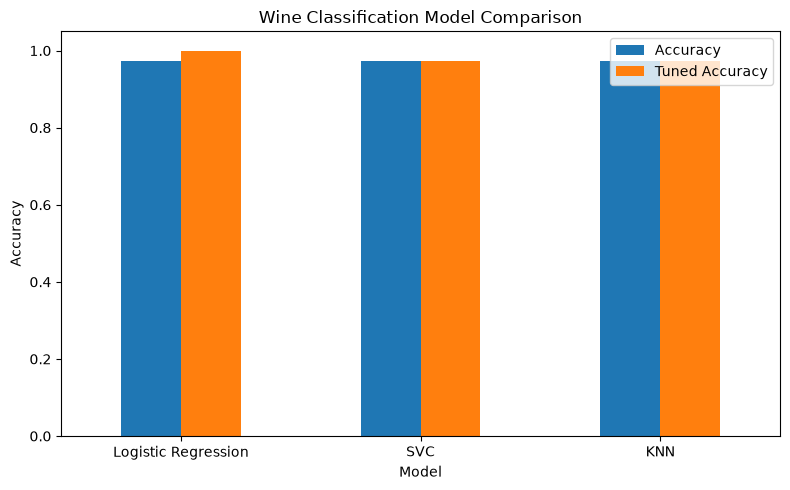

In [5]:
#Compare classification results
tuned_classification_df = pd.DataFrame(tuned_classification_results)

wine_comparison = classification_df.merge(
    tuned_classification_df,
    on="Model"
)

wine_comparison["Improvement"] = (
    wine_comparison["Tuned Accuracy"] -
    wine_comparison["Accuracy"]
)

print(wine_comparison)

wine_comparison.set_index("Model")[
    ["Accuracy", "Tuned Accuracy"]
].plot(kind="bar", figsize=(8, 5))

plt.title("Wine Classification Model Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Only the logistic regression showed an improvement in the model when it was tuned. The SVM and KNN had the same accuracy.

**Car Prices Dataset — Regression**

In [6]:
#Load and explore the used_cars dataset

df = pd.read_csv("used_cars.csv")

# Display the entire DataFrame
display(df)

# Display first 5 rows
display(df.head())

,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"
...,...,...,...,...,...,...,...,...,...,...,...,...
4004,Bentley,Continental GT Speed,2023,714 mi.,Gasoline,6.0L W12 48V PDI DOHC Twin Turbo,8-Speed Automatic with Auto-Shift,C / C,Hotspur,None reported,Yes,"$349,950"
4005,Audi,S4 3.0T Premium Plus,2022,"10,900 mi.",Gasoline,349.0HP 3.0L V6 Cylinder Engine Gasoline Fuel,Transmission w/Dual Shift Mode,Black,Black,None reported,Yes,"$53,900"
4006,Porsche,Taycan,2022,"2,116 mi.",NaN,Electric,Automatic,Black,Black,None reported,NaN,"$90,998"
4007,Ford,F-150 Raptor,2020,"33,000 mi.",Gasoline,450.0HP 3.5L V6 Cylinder Engine Gasoline Fuel,A/T,Blue,Black,None reported,Yes,"$62,999"


,brand,model,model_year,milage,fuel_type,engine,transmission,ext_col,int_col,accident,clean_title,price
0,Ford,Utility Police Interceptor Base,2013,"51,000 mi.",E85 Flex Fuel,300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...,6-Speed A/T,Black,Black,At least 1 accident or damage reported,Yes,"$10,300"
1,Hyundai,Palisade SEL,2021,"34,742 mi.",Gasoline,3.8L V6 24V GDI DOHC,8-Speed Automatic,Moonlight Cloud,Gray,At least 1 accident or damage reported,Yes,"$38,005"
2,Lexus,RX 350 RX 350,2022,"22,372 mi.",Gasoline,3.5 Liter DOHC,Automatic,Blue,Black,None reported,NaN,"$54,598"
3,INFINITI,Q50 Hybrid Sport,2015,"88,900 mi.",Hybrid,354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...,7-Speed A/T,Black,Black,None reported,Yes,"$15,500"
4,Audi,Q3 45 S line Premium Plus,2021,"9,835 mi.",Gasoline,2.0L I4 16V GDI DOHC Turbo,8-Speed Automatic,Glacier White Metallic,Black,None reported,NaN,"$34,999"


**Explore the dataset**

In [7]:
print(df.info())
print(df.isnull().sum())
print(df.columns.tolist())

<class 'pandas.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   brand         4009 non-null   str  
 1   model         4009 non-null   str  
 2   model_year    4009 non-null   int64
 3   milage        4009 non-null   str  
 4   fuel_type     3839 non-null   str  
 5   engine        4009 non-null   str  
 6   transmission  4009 non-null   str  
 7   ext_col       4009 non-null   str  
 8   int_col       4009 non-null   str  
 9   accident      3896 non-null   str  
 10  clean_title   3413 non-null   str  
 11  price         4009 non-null   str  
dtypes: int64(1), str(11)
memory usage: 892.6 KB
None
brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64
['brand', 'model', 'mod

In [14]:
#convert string to float 
# Remove dollar signs and commas
df["price"] = (
    df["price"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
)

# Convert prices to numeric values
df["price"] = pd.to_numeric(df["price"], errors="coerce")

# Check the results
print(df["price"].head())
print(df["price"].dtype)
print("Missing prices:", df["price"].isnull().sum())

0    10300
1    38005
2    54598
3    15500
4    34999
Name: price, dtype: int64
int64
Missing prices: 0


In [15]:
# Fill missing categorical values with "Unknown"
df["fuel_type"] = df["fuel_type"].fillna("Unknown")
df["accident"] = df["accident"].fillna("Unknown")
df["clean_title"] = df["clean_title"].fillna("Unknown")

# Check missing values again
print(df.isnull().sum())

brand           0
model           0
model_year      0
milage          0
fuel_type       0
engine          0
transmission    0
ext_col         0
int_col         0
accident        0
clean_title     0
price           0
dtype: int64


In [16]:
#Separate the features and target variable
X = df.drop("price", axis=1)
y = df["price"]

print("Features:", X.shape)
print("Target:", y.shape)

Features: (4009, 11)
Target: (4009,)


In [17]:
from sklearn.model_selection import train_test_split

# Convert categorical features into numerical values
X = pd.get_dummies(X, drop_first=True, dtype=int) #get dummies Converts categorical variables into numerical columns

#Split into Training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3207, 6460)
Testing data: (802, 6460)


**Train the three regression models**

In [18]:
from sklearn.pipeline import make_pipeline

# Define the three models
models = {
    "Linear Regression": LinearRegression(),
    "SVR": make_pipeline(StandardScaler(), SVR()),
    "KNN Regressor": make_pipeline(
        StandardScaler(), KNeighborsRegressor(n_neighbors=5)
    )
}

# Train each model
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully")

Linear Regression trained successfully
SVR trained successfully
KNN Regressor trained successfully


In [ ]:
**Evaluate model performance**

In [20]:
from sklearn.metrics import mean_squared_error, r2_score

results = []

for name, model in models.items():

    # Predict car prices
    y_pred = model.predict(X_test)

    # Evaluate performance
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    # Store results
    results.append({
        "Model": name,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

# Display comparison table
results_df = pd.DataFrame(results)

display(results_df)

,Model,MSE,RMSE,R2 Score
0,Linear Regression,2.059614e+10,143513.549640,-0.007660
1,SVR,2.079910e+10,144218.942201,-0.017590
2,KNN Regressor,2.036674e+10,142712.086197,0.003563


The RMSE of 143,513.55 indicates substantial prediction errors.
The negative R² score of -0.0077 means the model performs slightly worse than simply predicting the average car price in the test set.
This suggests that Linear Regression is not capturing the relationships between car features and prices effectively.

All three models performed poorly in predicting car prices

**Compare the models and show the best model**

In [21]:
best_model = results_df.loc[results_df["RMSE"].idxmin()]

print("Best Model:", best_model["Model"])
print("MSE:", round(best_model["MSE"], 2))
print("RMSE:", round(best_model["RMSE"], 2))
print("R2 Score:", round(best_model["R2 Score"], 4))

Best Model: KNN Regressor
MSE: 20366739546.72
RMSE: 142712.09
R2 Score: 0.0036


**Parameter tuning**

In [23]:
# Hyperparameters to test
param_grids = {
    "Linear Regression": {
        "fit_intercept": [True, False]
    },

    "SVR": {
        "svr__C": [1, 10, 100, 1000]
    },

    "KNN Regressor": {
        "kneighborsregressor__n_neighbors": [3, 5, 7, 9]
    }
}

tuned_results = []
parameter_results = []

for name, model in models.items():

    grid = GridSearchCV(
        model,
        param_grids[name],
        cv=3,
        scoring="neg_mean_squared_error",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    # Predict using best parameters
    y_pred = grid.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)

    tuned_results.append({
        "Model": name,
        "Best Parameters": grid.best_params_,
        "Tuned MSE": mse,
        "Tuned RMSE": rmse,
        "Tuned R2": r2
    })

    # Record each parameter combination's CV performance
    cv_results = pd.DataFrame(grid.cv_results_)

    for _, row in cv_results.iterrows():
        parameter_results.append({
            "Model": name,
            "Parameters": str(row["params"]),
            "CV RMSE": np.sqrt(-row["mean_test_score"])
        })

    print("\nModel:", name)
    print("Best Parameters:", grid.best_params_)
    print("Tuned R2:", round(r2, 4))

tuned_df = pd.DataFrame(tuned_results)
parameter_df = pd.DataFrame(parameter_results)

display(tuned_df)


Model: Linear Regression
Best Parameters: {'fit_intercept': True}
Tuned R2: -0.0077

Model: SVR
Best Parameters: {'svr__C': 1000}
Tuned R2: -0.0164

Model: KNN Regressor
Best Parameters: {'kneighborsregressor__n_neighbors': 3}
Tuned R2: 0.0098


,Model,Best Parameters,Tuned MSE,Tuned RMSE,Tuned R2
0,Linear Regression,{'fit_intercept': True},2.059614e+10,143513.549640,-0.007660
1,SVR,{'svr__C': 1000},2.077432e+10,144133.005591,-0.016378
2,KNN Regressor,{'kneighborsregressor__n_neighbors': 3},2.023990e+10,142266.996334,0.009769


In [24]:
#Compare perfomamnce before and after
comparison = results_df.merge(
    tuned_df,
    on="Model"
)

comparison["R2 Improvement"] = (
    comparison["Tuned R2"] - comparison["R2 Score"]
)

comparison["RMSE Improvement"] = (
    comparison["RMSE"] - comparison["Tuned RMSE"]
)

display(comparison[
    [
        "Model",
        "RMSE",
        "Tuned RMSE",
        "R2 Score",
        "Tuned R2",
        "R2 Improvement",
        "RMSE Improvement"
    ]
])

,Model,RMSE,Tuned RMSE,R2 Score,Tuned R2,R2 Improvement,RMSE Improvement
0,Linear Regression,143513.549640,143513.549640,-0.007660,-0.007660,0.000000,0.000000
1,SVR,144218.942201,144133.005591,-0.017590,-0.016378,0.001212,85.936610
2,KNN Regressor,142712.086197,142266.996334,0.003563,0.009769,0.006206,445.089863


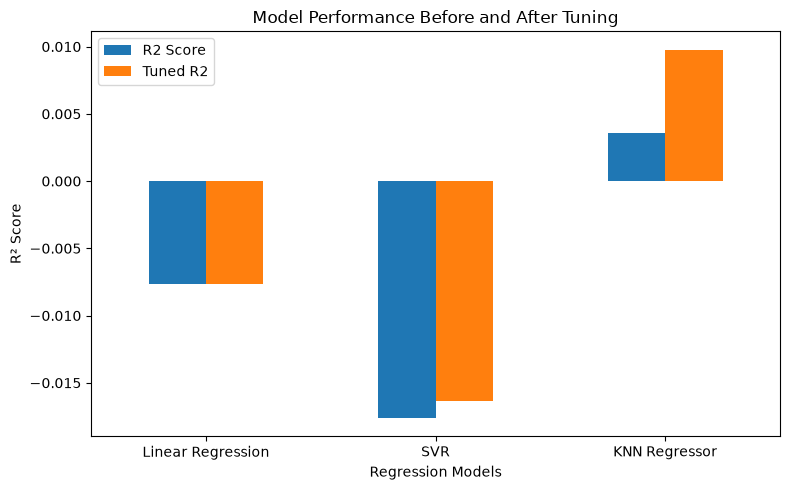

In [25]:
#Visualize the result
import matplotlib.pyplot as plt

comparison.set_index("Model")[
    ["R2 Score", "Tuned R2"]
].plot(kind="bar", figsize=(8, 5))

plt.title("Model Performance Before and After Tuning")
plt.ylabel("R² Score")
plt.xlabel("Regression Models")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

The purpose of parameter tuning was to improve the performance of the three regression models used to predict car prices. GridSearchCV was applied to test different hyperparameter values using cross-validation. The models were then evaluated using MSE, RMSE, and R².

Linear Regression: Changing fit_intercept affects whether the model includes an intercept in its predictions. Including an intercept generally helps unless there is a good reason to force the prediction through zero.
Support Vector Regressor: Increasing C makes the model penalize prediction errors more strongly. This can improve performance but may also increase overfitting.
KNN Regressor: Smaller values of k make predictions more sensitive to individual nearby cars, while larger values average prices across more vehicles. The best value balances overfitting and underfitting.

Linear Regression
The RMSE remained unchanged at 143,513.55, and the R² score remained at -0.0077. This indicates that parameter tuning did not improve the model's performance. The negative R² suggests that the model performs slightly worse than simply predicting the average car price for every observation.

Support Vector Regressor (SVR)
The RMSE decreased from 144,218.94 to 144,133.01, an improvement of approximately 85.94. The R² score also improved slightly from -0.0176 to -0.0164. Although tuning reduced prediction errors, the negative R² indicates that SVR still performs poorly at predicting car prices.

KNN Regressor
KNN achieved the best performance among the three models. Its RMSE decreased from 142,712.09 to 142,267.00, an improvement of approximately 445.09. Its R² score increased from 0.0036 to 0.0098, indicating a small improvement in its ability to explain car price variation.
However, an R² of 0.0098 means that the model explains only about 0.98% of the variation in car prices, which is extremely low.

Overall, parameter tuning improved performance slightly, but the models did not achieve satisfactory prediction accuracy. KNN performed best because it had the lowest RMSE and highest R² score.